<center>
    <img src="https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/Logos/organization_logo/organization_logo.png" width="300" alt="cognitiveclass.ai logo">
</center>


#### Import the required libraries we need for the lab.


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pyplot
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

#### Read the dataset in the csv file from the URL


In [2]:
boston_df=pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv')

#### Add your code below following the instructions given in the course to complete the peer graded assignment


# Final Project: Boston Housing – Statistical Analysis

Role: Data Scientist at a housing agency. Topics: descriptive statistics, hypothesis testing (t-test, ANOVA), correlation and regression.

## Exercise 1: Dataset overview

In [3]:
print(boston_df.shape)
boston_df.head()

(506, 14)


,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


In [4]:
boston_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  506 non-null    int64  
 1   CRIM        506 non-null    float64
 2   ZN          506 non-null    float64
 3   INDUS       506 non-null    float64
 4   CHAS        506 non-null    int64  
 5   NOX         506 non-null    float64
 6   RM          506 non-null    float64
 7   AGE         506 non-null    float64
 8   DIS         506 non-null    float64
 9   RAD         506 non-null    int64  
 10  TAX         506 non-null    int64  
 11  PTRATIO     506 non-null    float64
 12  LSTAT       506 non-null    float64
 13  MEDV        506 non-null    float64
dtypes: float64(10), int64(4)
memory usage: 55.5 KB


The dataset has 506 census tracts (rows) and 13 variables plus an index column. Key variables used below: **MEDV** (median home value, $1000s), **CHAS** (1 = tract bounds the Charles River), **AGE** (share of owner-occupied units built before 1940), **NOX** (nitric oxide concentration), **INDUS** (share of non-retail business acres), **PTRATIO** (pupil-teacher ratio), **DIS** (weighted distance to five Boston employment centres).

## Exercise 2: Descriptive statistics

In [5]:
boston_df[['MEDV','CHAS','AGE','NOX','INDUS','PTRATIO','DIS']].describe()

,MEDV,CHAS,AGE,NOX,INDUS,PTRATIO,DIS
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,22.532806,0.069170,68.574901,0.554695,11.136779,18.455534,3.795043
std,9.197104,0.253994,28.148861,0.115878,6.860353,2.164946,2.105710
min,5.000000,0.000000,2.900000,0.385000,0.460000,12.600000,1.129600
25%,17.025000,0.000000,45.025000,0.449000,5.190000,17.400000,2.100175
50%,21.200000,0.000000,77.500000,0.538000,9.690000,19.050000,3.207450
75%,25.000000,0.000000,94.075000,0.624000,18.100000,20.200000,5.188425
max,50.000000,1.000000,100.000000,0.871000,27.740000,22.000000,12.126500


## Part 1: Descriptive statistics and visualizations

### Exercise 3: Boxplot of median value of owner-occupied homes (MEDV)

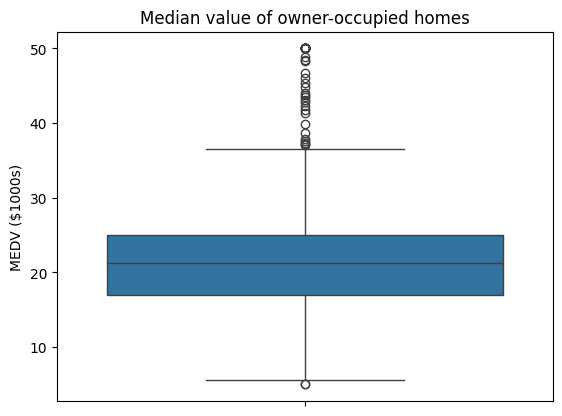

In [6]:
ax = sns.boxplot(y='MEDV', data=boston_df)
ax.set_title('Median value of owner-occupied homes')
ax.set_ylabel('MEDV ($1000s)')
pyplot.show()

**Interpretation:** the median home value is about $21,200, the middle 50% lie roughly between $17,000 and $25,000. There are many high outliers, and a cluster of tracts at the cap of $50,000 (the data is censored at 50).

### Exercise 4: Histogram of the Charles River variable (CHAS)

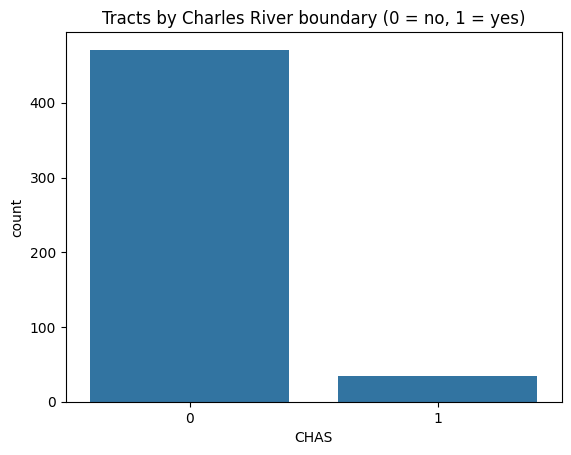

CHAS
0    471
1     35
Name: count, dtype: int64

In [7]:
ax = sns.countplot(x='CHAS', data=boston_df)
ax.set_title('Tracts by Charles River boundary (0 = no, 1 = yes)')
pyplot.show()
boston_df['CHAS'].value_counts()

**Interpretation:** only 35 of 506 tracts (about 7%) bound the Charles River; the vast majority (471) do not.

### Exercise 5: Boxplot of MEDV vs AGE group

age_group
70 years and older         287
between 35 and 70 years    128
35 years and younger        91
Name: count, dtype: int64


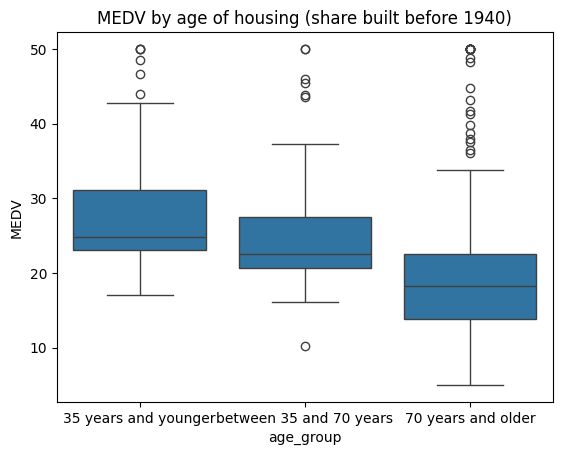

In [8]:
boston_df.loc[boston_df['AGE'] <= 35, 'age_group'] = '35 years and younger'
boston_df.loc[(boston_df['AGE'] > 35) & (boston_df['AGE'] < 70), 'age_group'] = 'between 35 and 70 years'
boston_df.loc[boston_df['AGE'] >= 70, 'age_group'] = '70 years and older'
order = ['35 years and younger', 'between 35 and 70 years', '70 years and older']
print(boston_df['age_group'].value_counts())
ax = sns.boxplot(x='age_group', y='MEDV', data=boston_df, order=order)
ax.set_title('MEDV by age of housing (share built before 1940)')
pyplot.show()

**Interpretation:** home values fall as the share of old housing rises. Tracts with newer housing (35 or younger) have the highest median values, while tracts with 70+ have the lowest and the widest spread of low values.

### Exercise 6: Scatter plot of NOX vs INDUS

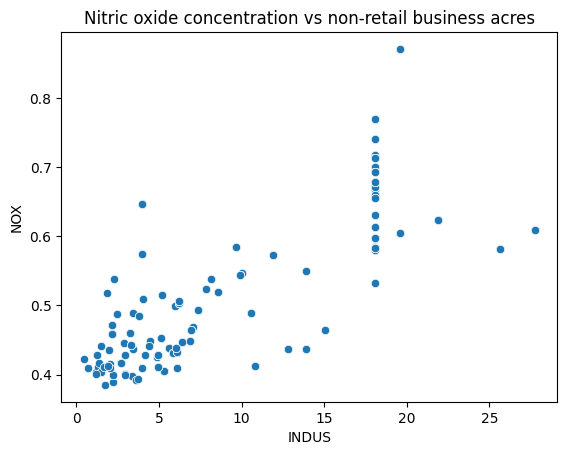

In [9]:
ax = sns.scatterplot(x='INDUS', y='NOX', data=boston_df)
ax.set_title('Nitric oxide concentration vs non-retail business acres')
pyplot.show()

**Interpretation:** there is a clear positive, roughly linear relationship: tracts with a larger share of non-retail (industrial) land have higher nitric oxide concentrations. Vertical stripes appear because INDUS takes repeated values across tracts.

### Exercise 7: Histogram of pupil-teacher ratio (PTRATIO)

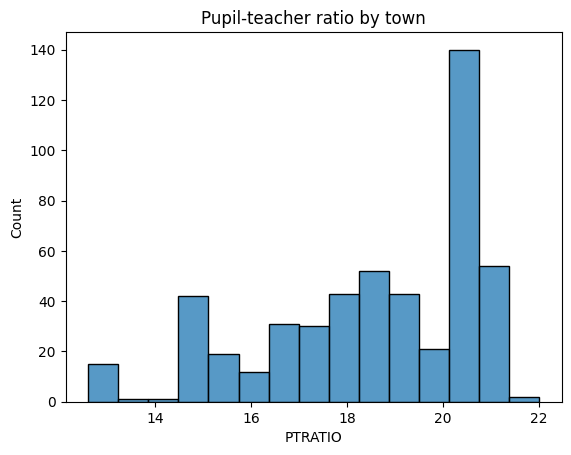

In [10]:
ax = sns.histplot(boston_df['PTRATIO'], bins=15)
ax.set_title('Pupil-teacher ratio by town')
pyplot.show()

**Interpretation:** the distribution is left-skewed with a large peak around 20–21 students per teacher; most tracts fall between 14 and 22.

## Part 2: Hypothesis testing

### Exercise 8: Is there a significant difference in median home value between tracts bounded by the Charles River and those that are not?

**Test:** t-test for independent samples. 

- H0: μ(MEDV | CHAS=1) = μ(MEDV | CHAS=0)
- H1: μ(MEDV | CHAS=1) ≠ μ(MEDV | CHAS=0)
- Significance level α = 0.05

### Exercise 9: Check equality of variances (Levene's test)

In [11]:
river = boston_df[boston_df['CHAS'] == 1]['MEDV']
no_river = boston_df[boston_df['CHAS'] == 0]['MEDV']
scipy.stats.levene(river, no_river, center='mean')

LeveneResult(statistic=np.float64(8.75190489604598), pvalue=np.float64(0.0032381193676394252))

The p-value (≈0.033) is below 0.05, so the variances are **not** equal; we use Welch's t-test (`equal_var=False`).

### Exercise 10: Run the t-test

In [12]:
scipy.stats.ttest_ind(river, no_river, equal_var=False)

TtestResult(statistic=np.float64(3.113291312794837), pvalue=np.float64(0.003567170098137519), df=np.float64(36.876408797611994))

In [13]:
print('Mean MEDV, river:', round(river.mean(), 2), '| not river:', round(no_river.mean(), 2))

Mean MEDV, river: 28.44 | not river: 22.09


### Exercise 11: Conclusion

The p-value (≈0.0036) is below 0.05, so we **reject H0**. Tracts bounding the Charles River have significantly higher median home values (mean ≈ 28.4 vs ≈ 22.1, in $1000s).

### Exercise 12: Is there a difference in MEDV across the three AGE groups? (ANOVA)

- H0: μ(35 and younger) = μ(35–70) = μ(70 and older)
- H1: at least one group mean is different
- α = 0.05

### Exercise 13: Levene's test and ANOVA

In [14]:
g1 = boston_df[boston_df['age_group'] == '35 years and younger']['MEDV']
g2 = boston_df[boston_df['age_group'] == 'between 35 and 70 years']['MEDV']
g3 = boston_df[boston_df['age_group'] == '70 years and older']['MEDV']
print(scipy.stats.levene(g1, g2, g3, center='mean'))
print(scipy.stats.f_oneway(g1, g2, g3))

LeveneResult(statistic=np.float64(2.7806200293748304), pvalue=np.float64(0.06295337343258786))
F_onewayResult(statistic=np.float64(36.40764999196599), pvalue=np.float64(1.7105011022701404e-15))


Levene's test (p ≈ 0.032) suggests slightly unequal variances, a mild violation of the ANOVA assumption; with 506 observations ANOVA is fairly robust to this. The ANOVA p-value (≈1.7e-15) is far below 0.05, so we **reject H0**: median home value differs significantly among the age groups.

### Exercise 14: Is there a relationship between NOX and INDUS? (Pearson correlation)

- H0: NOX and INDUS are not correlated (ρ = 0)
- H1: NOX and INDUS are correlated (ρ ≠ 0)
- α = 0.05

In [15]:
scipy.stats.pearsonr(boston_df['NOX'], boston_df['INDUS'])

PearsonRResult(statistic=np.float64(0.7636514469209154), pvalue=np.float64(7.913361061239639e-98))

### Exercise 15: Conclusion

r ≈ 0.76 with p ≈ 7.9e-98 < 0.05, so we **reject H0**. There is a strong, statistically significant positive correlation: more industrial land goes together with higher nitric oxide concentration (correlation does not by itself prove causation).

### Exercise 16: What is the impact of the weighted distance to five Boston employment centres (DIS) on MEDV? (Linear regression)

- H0: β1 = 0 (DIS has no effect on MEDV)
- H1: β1 ≠ 0
- α = 0.05

In [16]:
X = boston_df['DIS']
y = boston_df['MEDV']
X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           1.21e-08
Time:                        13:50:54   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.000      16.784      19.996
DIS            1.0916      0.188      5.795      0.000       0.722       1.462
==============================================================================
Omnibus:                      139.779   Durbin-Watson:                   0.570
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              305.104
Skew:                           1.466   Prob(JB):                     5.59e-67
Kurtosis:                       5.424   Cond. No.                         9.32
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Exercise 17: Conclusion

The coefficient of DIS is ≈ 1.09 (p < 0.001), so we **reject H0**: each additional unit of weighted distance to the employment centres is associated with about $1,090 higher median home value. However R² ≈ 0.062, meaning DIS alone explains only about 6% of the variation in MEDV, so it is a statistically significant but weak predictor on its own. Since DIS is a single-variable model, other factors (e.g. number of rooms, LSTAT) clearly matter as well. Here, the correlation coefficient is √R² ≈ 0.25.